# Lab 5 | Batch vs Stochastic vs Mini-batch Gradient Descent
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/24pwai0015-max/deep-learning-labs/blob/main/Lab5_Batch_vs_Stochastic_vs_MiniBatch.ipynb)

**Course:** Deep Learning Foundations | Practical Labs  
**Author:** Arsalan

This notebook keeps **SGD(learning_rate=0.02)** fixed and changes only the `batch_size` argument of `model.fit()` (600 = full batch, 1 = stochastic, 32 = mini-batch) for an ANN, an MLP and a CNN on a small Fashion-MNIST subset (600 train / 200 validation / 500 test).

> **How to run:** In Google Colab choose *Runtime → Run all*. Keras downloads the public dataset on first use.
> Numbers (especially *seconds*) can differ slightly between machines, so always report values from **your own** run.


## 1. Settings and data preparation

In [1]:
# LAB 5: Compare full-batch, stochastic and mini-batch gradient descent.
# Run in Google Colab or locally after: pip install tensorflow numpy matplotlib
# Models: one-hidden-layer ANN, two-hidden-layer MLP and a compact CNN.
# Key control: use the SAME tf.keras.optimizers.SGD(learning_rate=0.02) everywhere.
# The gradient descent technique is selected by model.fit(..., batch_size=...).

import os  # Control the quantity of TensorFlow start-up messages.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Reduce routine TensorFlow logging.
import csv  # Create a table that can be opened in Excel.
import math  # Calculate the number of weight updates per epoch.
import time  # Time each training setup on the current machine.
from pathlib import Path  # Make portable filenames and result folders.
import numpy as np  # Prepare reproducible subsets of image examples.
import matplotlib.pyplot as plt  # Visualize measured validation accuracy.
import tensorflow as tf  # Build and optimize all three neural networks.

SEED = 42  # Specify a reproducible dataset selection and random seed.
TRAIN_N = 600  # Keep single-example SGD feasible during a short classroom lab.
VAL_N = 200  # Reserve 200 images for validation after every epoch.
TEST_N = 500  # Use held-out test images after training each run.
EPOCHS = 3  # Use the same number of complete data passes in every run.
LEARNING_RATE = 0.02  # Hold the SGD learning rate constant across techniques.
OUT = Path("lab5_gradient_descent_results")  # Select a folder for CSV data and figures.
OUT.mkdir(parents=True, exist_ok=True)  # Create the output folder if it is missing.
tf.keras.utils.set_random_seed(SEED)  # Seed the supported Python and machine-learning RNGs.

(x_all, y_all), (x_test_all, y_test_all) = tf.keras.datasets.fashion_mnist.load_data()  # Load clothes images.
rng = np.random.default_rng(SEED)  # Set an independent reproducible NumPy random source.
chosen_ids = rng.permutation(len(x_all))[:TRAIN_N + VAL_N]  # Randomly select 800 development examples.
test_ids = rng.permutation(len(x_test_all))[:TEST_N]  # Randomly select separate test examples.
x_train = x_all[chosen_ids[:TRAIN_N]].astype("float32") / 255.0  # Scale training images to 0..1.
y_train = y_all[chosen_ids[:TRAIN_N]]  # Select the training target classes.
x_val = x_all[chosen_ids[TRAIN_N:]].astype("float32") / 255.0  # Scale validation images to 0..1.
y_val = y_all[chosen_ids[TRAIN_N:]]  # Select the validation target classes.
x_test = x_test_all[test_ids].astype("float32") / 255.0  # Scale the final held-out images.
y_test = y_test_all[test_ids]  # Select their correct class labels.
print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)  # Confirm sizes.


Train: (600, 28, 28) | Validation: (200, 28, 28) | Test: (500, 28, 28)


## 2. Model definitions and batch regimes

In [2]:
def build_ann():  # Make the shallow fully connected neural network.
    return tf.keras.Sequential([  # Construct the layers in sequential order.
        tf.keras.layers.Input(shape=(28, 28)),  # Accept a 28-by-28 image.
        tf.keras.layers.Flatten(),  # Transform the image pixels into a vector.
        tf.keras.layers.Dense(64, activation="relu"),  # Add one hidden Dense layer.
        tf.keras.layers.Dense(10, activation="softmax"),  # Predict the 10 output classes.
    ])  # Complete the shallow ANN.

def build_mlp():  # Make a deeper multilayer perceptron architecture.
    return tf.keras.Sequential([  # Construct a fully connected model.
        tf.keras.layers.Input(shape=(28, 28)),  # Accept a grayscale image.
        tf.keras.layers.Flatten(),  # Flatten the input into 784 numeric features.
        tf.keras.layers.Dense(128, activation="relu"),  # Add the first hidden layer.
        tf.keras.layers.Dense(64, activation="relu"),  # Add the second hidden layer.
        tf.keras.layers.Dense(10, activation="softmax"),  # Predict the clothing classes.
    ])  # Complete the MLP.

def build_cnn():  # Build a compact convolutional classifier.
    return tf.keras.Sequential([  # Use the same framework as the other models.
        tf.keras.layers.Input(shape=(28, 28, 1)),  # Expect an explicit grayscale channel.
        tf.keras.layers.Conv2D(16, 3, activation="relu"),  # Learn basic visual features.
        tf.keras.layers.MaxPooling2D(),  # Reduce the feature-map sizes.
        tf.keras.layers.Conv2D(32, 3, activation="relu"),  # Learn higher-level patterns.
        tf.keras.layers.MaxPooling2D(),  # Downsample a second time.
        tf.keras.layers.Flatten(),  # Transform the feature maps into a vector.
        tf.keras.layers.Dense(32, activation="relu"),  # Combine the visual features.
        tf.keras.layers.Dense(10, activation="softmax"),  # Output the class probabilities.
    ])  # Complete the CNN network.

MODELS = [("ANN", build_ann), ("MLP", build_mlp), ("CNN", build_cnn)]  # List the three model designs.
TECHNIQUES = [("Full batch", TRAIN_N), ("Stochastic", 1), ("Mini-batch", 32)]  # Change batch_size only.


## 3. Training loop (weights reset before every regime) and graphs

In [3]:
results = []  # Collect the results of three models times three regimes.
epoch_rows = []  # Collect per-epoch validation accuracy for every run.
for model_name, builder in MODELS:  # Evaluate each network architecture in turn.
    if model_name == "CNN":  # Convolution requires four-dimensional image tensors.
        x_tr = x_train[..., np.newaxis]  # Add one channel to the training images.
        x_va = x_val[..., np.newaxis]  # Add one channel to the validation images.
        x_te = x_test[..., np.newaxis]  # Add one channel to the testing images.
    else:  # Fully connected networks accept the original 28-by-28 images.
        x_tr, x_va, x_te = x_train, x_val, x_test  # Reuse the same images without a channel axis.
    tf.keras.utils.set_random_seed(SEED)  # Reproduce this network's original initialization.
    reference = builder()  # Construct a new, as-yet-untrained reference model.
    initial_weights = reference.get_weights()  # Save the identical starting parameters.
    del reference  # Free the no-longer-needed reference network.
    histories = {}  # Store each technique's true validation accuracy curve.
    for technique, batch_size in TECHNIQUES:  # Change only the batch size within this model.
        tf.keras.utils.set_random_seed(SEED)  # Reset randomness between independent runs.
        model = builder()  # Rebuild the very same architecture.
        model.set_weights(initial_weights)  # Reset exactly the same starting weights.
        optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE)  # Fix the optimizer AND its rate.
        model.compile(optimizer=optimizer,  # Attach the fixed SGD optimizer.
                      loss="sparse_categorical_crossentropy",  # Use the integer-label loss.
                      metrics=["accuracy"])  # Track classification accuracy.
        steps_per_epoch = math.ceil(TRAIN_N / batch_size)  # Count the expected updates per epoch.
        start = time.perf_counter()  # Begin timing the actual training run.
        history = model.fit(x_tr, y_train,  # Train on the fixed training subset.
                            validation_data=(x_va, y_val),  # Validate after every epoch.
                            epochs=EPOCHS,  # Use the same number of epochs every time.
                            batch_size=batch_size,  # The ONLY setting that changes: 600, 1 or 32.
                            shuffle=True,  # Shuffle the training data each epoch.
                            verbose=0)  # Train without verbose progress logs.
        elapsed = time.perf_counter() - start  # Record the elapsed wall-clock training time.
        test_loss, test_accuracy = model.evaluate(x_te, y_test, verbose=0)  # Evaluate on held-out examples.
        best_val = max(history.history["val_accuracy"])  # Check the strongest validation epoch.
        histories[technique] = history.history["val_accuracy"]  # Save the actual accuracy trajectory.
        results.append({  # Save the metrics together with the update counts.
            "model": model_name,  # Architecture name.
            "method": technique,  # Full batch, stochastic or mini-batch.
            "batch_size": batch_size,  # Examples per gradient update.
            "updates_per_epoch": steps_per_epoch,  # Weight updates in one epoch.
            "total_updates": EPOCHS * steps_per_epoch,  # Weight updates over all epochs.
            "best_val_accuracy": round(best_val, 4),  # Best validation accuracy over the epochs.
            "test_accuracy": round(test_accuracy, 4),  # Accuracy on the held-out test subset.
            "test_loss": round(test_loss, 4),  # Loss on the held-out test subset.
            "train_seconds": round(elapsed, 2),  # Training time on this machine.
        })  # Finish the result row.
        for epoch_no, acc in enumerate(history.history["val_accuracy"], start=1):  # Walk through epochs.
            epoch_rows.append({"model": model_name, "method": technique,  # Identify the run.
                               "epoch": epoch_no, "val_accuracy": round(acc, 4)})  # Save its accuracy.
        print(f"{model_name:3} | {technique:10} | batch={batch_size:3} | steps/epoch={steps_per_epoch:3} "
              f"| val={best_val:.3f} | test={test_accuracy:.3f}")  # Show the observations.
    plt.figure(figsize=(8, 4.5))  # Create the current network's accuracy plot.
    for method, curve in histories.items():  # Compare the three real training histories.
        plt.plot(range(1, EPOCHS + 1), curve, marker="o", label=method)  # Plot the observed accuracies.
    plt.title(f"{model_name}: validation accuracy by batch regime")  # Identify the current architecture.
    plt.xlabel("Epoch")  # Put complete dataset passes on the horizontal axis.
    plt.ylabel("Validation accuracy")  # Show validation performance on the vertical axis.
    plt.xticks(range(1, EPOCHS + 1))  # Display integer epoch tick marks.
    plt.grid(alpha=0.25)  # Make the slopes easier to compare.
    plt.legend()  # Label the full-batch, stochastic and mini-batch curves.
    plt.tight_layout()  # Avoid clipping axis annotations.
    plt.savefig(OUT / f"{model_name.lower()}_batch_methods.png", dpi=160)  # Save the current model chart.
    plt.close()  # Release this figure's memory.


ANN | Full batch | batch=600 | steps/epoch=  1 | val=0.185 | test=0.178


ANN | Stochastic | batch=  1 | steps/epoch=600 | val=0.660 | test=0.602


ANN | Mini-batch | batch= 32 | steps/epoch= 19 | val=0.670 | test=0.630


MLP | Full batch | batch=600 | steps/epoch=  1 | val=0.140 | test=0.138


MLP | Stochastic | batch=  1 | steps/epoch=600 | val=0.660 | test=0.616


MLP | Mini-batch | batch= 32 | steps/epoch= 19 | val=0.625 | test=0.612


CNN | Full batch | batch=600 | steps/epoch=  1 | val=0.155 | test=0.134


CNN | Stochastic | batch=  1 | steps/epoch=600 | val=0.660 | test=0.622


CNN | Mini-batch | batch= 32 | steps/epoch= 19 | val=0.415 | test=0.352


## 4. Save the measured results as CSV

In [4]:
with (OUT / "batch_method_results.csv").open("w", newline="", encoding="utf-8") as file:  # Open the CSV.
    writer = csv.DictWriter(file, fieldnames=list(results[0].keys()))  # Define the CSV columns.
    writer.writeheader()  # Save informative table headings.
    writer.writerows(results)  # Save all nine measured runs.
with (OUT / "epoch_validation_accuracy.csv").open("w", newline="", encoding="utf-8") as file:  # Second CSV.
    writer = csv.DictWriter(file, fieldnames=list(epoch_rows[0].keys()))  # Columns for the epoch table.
    writer.writeheader()  # Write the column names.
    writer.writerows(epoch_rows)  # Write the per-epoch validation accuracies.
print("CAUTION: Equal epochs do NOT mean equal updates when the batch size differs.")  # Key limitation.
print(f"Results and plots saved to: {OUT.resolve()}")  # Show the location of the output files.


CAUTION: Equal epochs do NOT mean equal updates when the batch size differs.
Results and plots saved to: /home/claude/work/lab5/lab5_gradient_descent_results


## Results: measured table and graphs
The cell below only *reads back* the files written above.

Measured results (batch_method_results.csv):


,model,method,batch_size,updates_per_epoch,total_updates,best_val_accuracy,test_accuracy,test_loss,train_seconds
0,ANN,Full batch,600,1,3,0.185,0.178,2.2445,0.87
1,ANN,Stochastic,1,600,1800,0.660,0.602,1.0941,4.02
2,ANN,Mini-batch,32,19,57,0.670,0.630,1.3086,1.07
3,MLP,Full batch,600,1,3,0.140,0.138,2.3060,0.87
4,MLP,Stochastic,1,600,1800,0.660,0.616,1.1046,4.16
5,MLP,Mini-batch,32,19,57,0.625,0.612,1.3438,0.88
6,CNN,Full batch,600,1,3,0.155,0.134,2.2917,1.49
7,CNN,Stochastic,1,600,1800,0.660,0.622,0.9566,6.90
8,CNN,Mini-batch,32,19,57,0.415,0.352,2.0780,1.50


Validation accuracy per epoch:


epoch                 1      2      3
model method                         
ANN   Full batch  0.140  0.150  0.185
      Mini-batch  0.530  0.645  0.670
      Stochastic  0.625  0.645  0.660
CNN   Full batch  0.135  0.155  0.145
      Mini-batch  0.295  0.325  0.415
      Stochastic  0.545  0.630  0.660
MLP   Full batch  0.080  0.100  0.140
      Mini-batch  0.335  0.550  0.625
      Stochastic  0.610  0.650  0.660

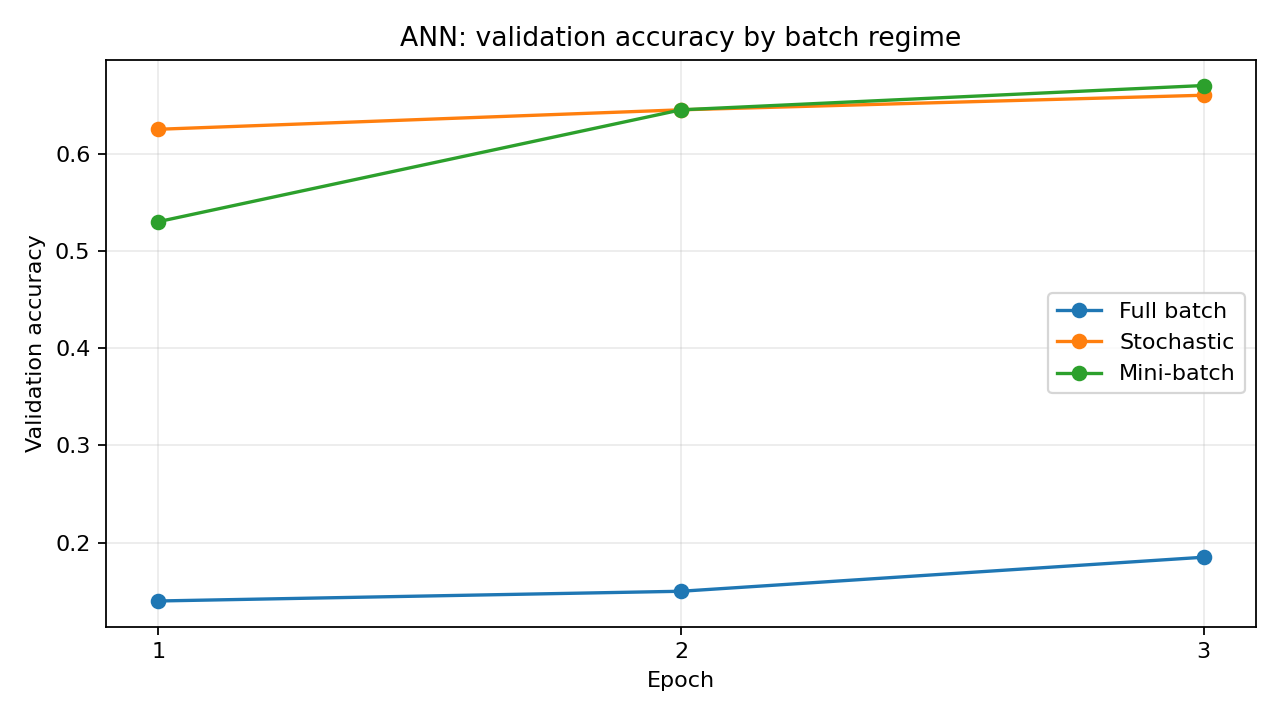

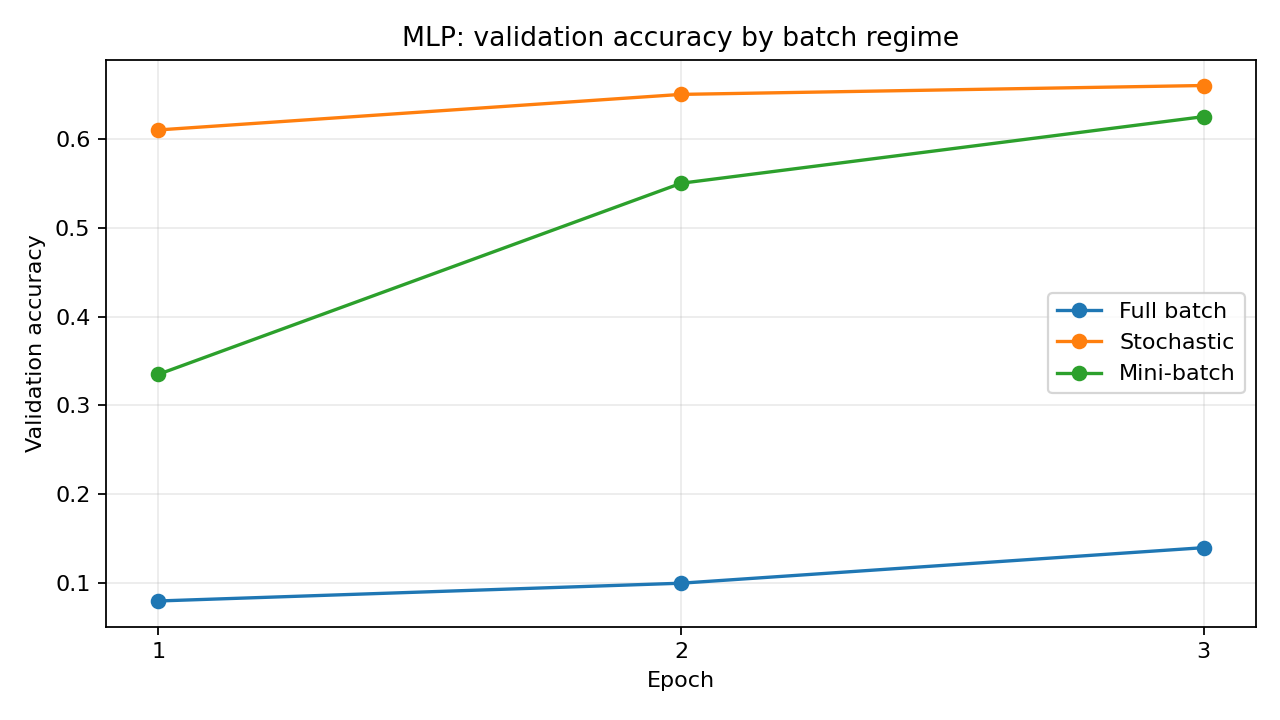

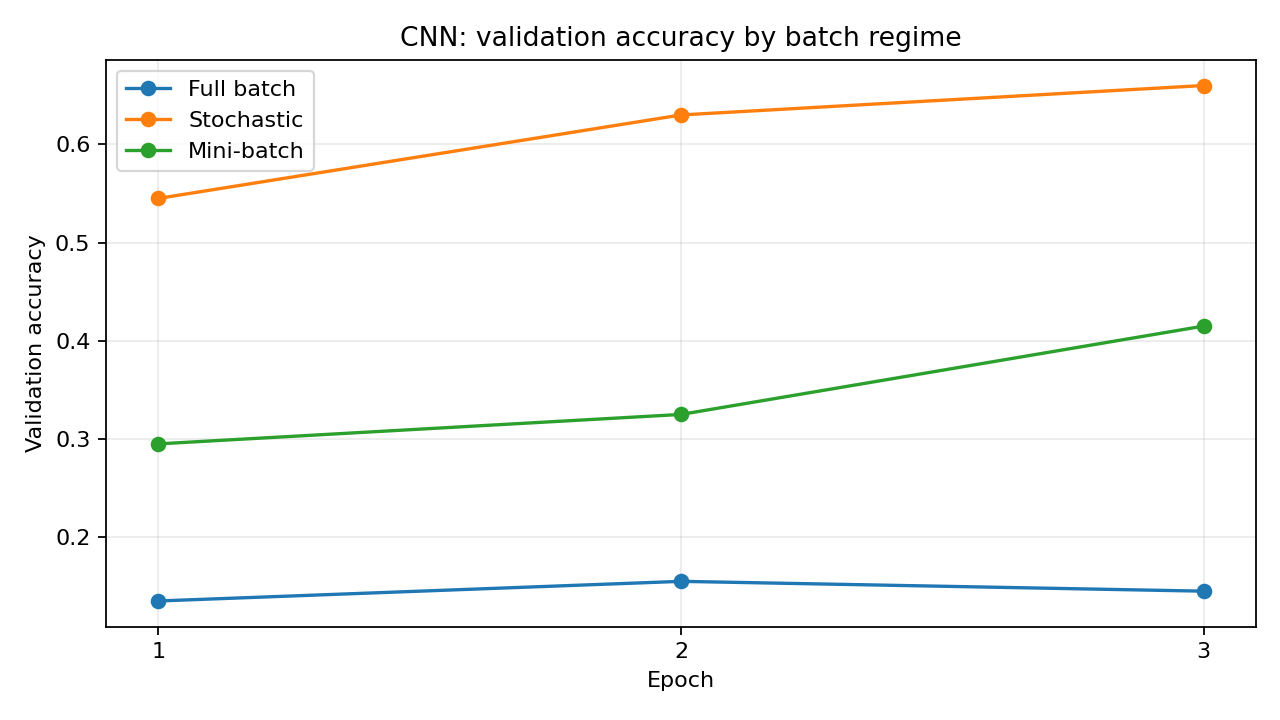

In [5]:
import pandas as pd  # Read the CSV files back as tables.
from IPython.display import Image, display  # Show the saved graphs inside the notebook.
print("Measured results (batch_method_results.csv):")  # Introduce the main table.
display(pd.read_csv(OUT / "batch_method_results.csv"))  # Show the real measured table.
print("Validation accuracy per epoch:")  # Introduce the convergence table.
display(pd.read_csv(OUT / "epoch_validation_accuracy.csv")  # Load the per-epoch values.
        .pivot_table(index=["model", "method"], columns="epoch", values="val_accuracy"))  # One row per run.
for name in ["ann", "mlp", "cnn"]:  # Show the graph of each architecture.
    display(Image(filename=str(OUT / f"{name}_batch_methods.png")))  # Display the saved PNG.


## Discussion

Stochastic training (batch size 1) performs the most updates per epoch: 600, against 19 for mini-batch (600 / 32, rounded up) and only 1 for full batch, because one update is made per batch and the number of batches is the training size divided by the batch size. Over three epochs that is 1800, 57 and 3 updates. Noisy single-example gradients make the path jagged, yet stochastic training still reached 0.60 to 0.62 test accuracy for all three models. The noise is costly per update, though: for the ANN and MLP, mini-batch matched it (0.630 and 0.612) with about 30 times fewer updates and roughly a quarter of the time. Full batch stayed near chance (0.134 to 0.178) because three steps at a rate of 0.02 are far too few. Three equal-epoch runs are not a matched-update comparison: equal epochs mean equal passes over the data but very different numbers of weight updates, so accuracy differences mix the effect of batch size with the effect of update count. These are also single-seed results on 600 training images.

### What changed, what stayed fixed, limitations
- **Changed:** only `batch_size` in `model.fit()` (600, 1, 32); the architecture changes only between the three blocks (ANN, MLP, CNN).
- **Fixed:** `SGD(learning_rate=0.02)`, EPOCHS = 3, image subsets, seed, and the starting weights of each model (restored before every run).
- **Limitations:** equal epochs do not give equal updates (3, 1800 and 57), so this is not a matched-update comparison; one seed per run; a very small training set (600 images); an untuned learning rate; and training seconds measured on one CPU.

### Interpretation
**Why do updates differ?** Steps per epoch = ceil(training size / batch size): ceil(600/600) = 1, ceil(600/1) = 600 and ceil(600/32) = 19.

**Which regime is fastest?** Mini-batch and full batch were fastest in seconds (about 0.9 to 1.5 s). Stochastic took 4.0 to 6.9 s because 1800 tiny steps cannot use vectorized computation, so per-step overhead most likely dominates (not separately measured).

**How to interpret accuracy** Compare accuracy together with the number of updates. Full batch scored low because it was barely trained; the CNN's mini-batch score (0.352) is likewise low because 57 updates are not enough for it at this rate.

**A stronger follow-up** Match the total number of updates (or the training time), repeat with several seeds, and tune the learning rate separately for each batch size.

*Numbers above come from the run stored in this notebook; re-running (e.g. in Colab) may change seconds and slightly change accuracies.*